# Precio internacional del aceite (índice de la FAO)

Este notebook replica el análisis hecho para la tasa de desocupación, ahora con el índice de precios de los aceites

Como la serie es un índice y no una tasa, varias partes del análisis original cambian: la forma de medir la variación en 12 meses, las unidades de los ejes y los valores que estaban fijados para la escala de la desocupación. Cada cambio se justifica en su sección. Las preguntas sobre la serie (frecuencia, unidad y fecha de inicio) se responden en la celda siguiente, antes de programar, y se verifican con código en la sección 2.

**Antes de ejecutar:**
1. `Entorno de ejecución → Cambiar tipo de entorno de ejecución → R`.
2. Abre el panel de archivos (ícono de carpeta a la izquierda) y sube `EI_PROD_BAS_AL (Aceite).xlsx`.
3. `Entorno de ejecución → Ejecutar todas`.

## Revisión del archivo (antes de programar)
Antes de escribir código se abrió el archivo `EI_PROD_BAS_AL (Aceite).xlsx`. Tiene tres hojas: `Cuadro`, con los datos; `Metadatos`, con la descripción de la serie; y `Series`, con su código.

- **¿Cuál es la frecuencia de la serie?** Mensual. La columna `Periodo` de `Cuadro` tiene una fecha por mes, siempre el día 1, y `Metadatos` indica "Frecuencia: MENSUAL".
- **¿En qué unidad está medida?** En un índice, no en una tasa en %. La hoja `Series` describe la serie como "Precio del aceite (Índice 2014-2016=100)" y `Metadatos` indica "Unidad: Índice". El valor 100 corresponde al promedio de 2014–2016: por ejemplo, el último dato, 196,9, significa un precio 96,9% sobre ese promedio. Además, la mayoría de los valores supera 100, algo imposible para una tasa que mide una parte de un total, como la desocupación.
- **¿Desde qué fecha hay datos?** Desde enero de 2010 hasta agosto de 2026, es decir, 200 meses. Según `Metadatos`, la serie existe en la base del Banco Central desde enero de 1990, pero el archivo descargado parte en 2010.

**Qué implica para el código.** En `Cuadro`, la fila 1 tiene el título, la 2 está vacía y la 3 tiene los encabezados (`Periodo` y `1. Aceite`), así que la lectura debe saltar 2 filas, igual que con la desocupación. Como la serie es mensual, retroceder 12 observaciones equivale a retroceder un año. Y como es un índice, la variación en 12 meses debe medirse en porcentaje. La sección 2 verifica todo esto con código.

## 1. Paquetes

In [1]:
# Colab (R) ya trae tidyverse; solo instala lo que falte
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl); library(dplyr); library(ggplot2); library(scales); library(tidyr)
})

## 2. Lectura y limpieza de datos

Antes de usar los datos se comprueba que el archivo tenga la estructura que supone el código. Si se salta un número equivocado de filas, los encabezados quedan mal: la lectura falla o, peor, entrega columnas corridas sin aviso. Por eso la celda siguiente hace dos cosas:

1. **Inspección del archivo.** Se listan sus hojas y se exige que exista `Cuadro`, la que contiene los datos. Luego se muestran las tres primeras filas de esa hoja tal como están en el Excel, sin saltar nada, para ver en qué fila están los encabezados. Por último se muestran las hojas `Metadatos` y `Series`, que describen la serie.
2. **Lectura y comprobaciones.** Se leen los datos saltando dos filas y se verifica que las columnas se llamen exactamente `Periodo` y `1. Aceite`. También se verifica que haya un dato por mes, sin repetidos ni huecos, y se calculan dos cifras que sirven para identificar la unidad de la serie. Si alguna comprobación falla, el código se detiene con un error en vez de seguir con datos equivocados.

In [2]:
archivo <- list.files(c("/content", "."), pattern = "\\.xlsx$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el .xlsx. Súbelo desde el panel de archivos (ícono de carpeta).")
cat("Leyendo:", archivo, "\n")

hojas <- excel_sheets(archivo)
cat("Hojas del archivo:", paste(hojas, collapse = ", "), "\n")
stopifnot("Cuadro" %in% hojas)
suppressMessages(read_excel(archivo, sheet = "Cuadro", range = "A1:B3", col_names = FALSE))

read_excel(archivo, sheet = "Metadatos", col_names = c("campo", "valor")) |> filter(campo != "Notas")
read_excel(archivo, sheet = "Series")

# skip = 2: se saltan el título (fila 1) y la fila vacía (fila 2); la fila 3 pasa a ser el encabezado
raw <- read_excel(archivo, sheet = "Cuadro", skip = 2)
names(raw)
stopifnot(identical(names(raw)[1:2], c("Periodo", "1. Aceite")))   # se saltó el número correcto de filas

df <- raw |>
  select(fecha = 1, indice = 2) |>
  mutate(fecha = as.Date(fecha), indice = as.numeric(indice)) |>
  filter(!is.na(fecha), !is.na(indice)) |>
  arrange(fecha) |>
  mutate(
    anio      = as.integer(format(fecha, "%Y")),
    mes       = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(indice, rep(1/12, 12), sides = 1)),  # promedio móvil 12 meses
    var_12m   = (indice / dplyr::lag(indice, 12) - 1) * 100                   # variación % vs. mismo mes del año anterior
  )

# Frecuencia: todas las fechas son día 1, ninguna se repite y no faltan meses
# (lag(indice, 12) equivale al mismo mes del año anterior solo si se cumple esto)
stopifnot(all(format(df$fecha, "%d") == "01"), !anyDuplicated(df$fecha))
stopifnot(nrow(df) == length(seq(min(df$fecha), max(df$fecha), by = "month")))
cat("Observaciones:", nrow(df), "| desde", format(min(df$fecha)), "hasta", format(max(df$fecha)), "\n")

# Unidad: si la base es el promedio 2014-2016, el promedio de esos 36 meses debe ser 100
cat("Promedio del índice en 2014-2016:", round(mean(df$indice[df$anio %in% 2014:2016]), 2), "\n")
cat("Meses con el índice sobre 100:", sum(df$indice > 100), "de", nrow(df), "\n")

summary(df$indice)    # nivel del índice (2014-2016 = 100)
summary(df$var_12m)   # variación % en 12 meses (los primeros 12 meses quedan NA)
tail(df, 12)          # últimos 12 meses

Leyendo: ./EI_PROD_BAS_AL (Aceite).xlsx 
Hojas del archivo: Cuadro, Metadatos, Series 


...1,...2
<chr>,<chr>
Índice de precios de alimentos,NA
NA,NA
Periodo,1. Aceite


campo,valor
<chr>,<chr>
Nombre y/o definición,Índice de precios de alimentos
Unidad,Índice
Frecuencia,MENSUAL
Fuente,FAO
Última actualización,08-09-2026
Primera observación,01-01-1990
Última observación,01-08-2026


Serie,Descripción
<chr>,<chr>
F019.PPBA.INP.46A.M,"Precio del aceite (Índice 2014-2016=100), FAO, Mensual, Índice"


[1] "Periodo"   "1. Aceite"

Observaciones: 200 | desde 2010-01-01 hasta 2026-08-01 
Promedio del índice en 2014-2016: 100 
Meses con el índice sobre 100: 145 de 200 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  76.59   98.18  120.96  126.68  152.79  251.83 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
-48.228 -14.982  -0.659   5.776  21.912 124.866      12 

fecha,indice,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2025-09-01,167.9269,2025,9,159.9630,17.9578668
2025-10-01,169.3892,2025,10,161.3524,10.9172687
2025-11-01,165.0066,2025,11,161.4276,0.5501301
2025-12-01,165.2038,2025,12,161.6878,1.9266502
2026-01-01,168.6491,2026,1,162.9896,10.2080056
2026-02-01,174.2249,2026,2,164.5091,11.6890443
2026-03-01,183.0878,2026,3,166.2870,13.1898447
2026-04-01,193.9390,2026,4,169.2803,22.7309825
2026-05-01,184.9877,2026,5,172.0093,21.5113844


### Verificación de la lectura
Las salidas de la celda anterior confirman lo revisado antes de programar:
- **Hoja y filas que se saltan.** La lista de hojas incluye `Cuadro`; sus tres primeras filas muestran el título, una fila vacía y los encabezados; y después de saltar dos filas las columnas se llaman exactamente `Periodo` y `1. Aceite`. Ninguna comprobación detuvo el código, así que la lectura es correcta.
- **Frecuencia.** Hay 200 observaciones, todas el día 1 de cada mes, sin fechas repetidas y sin meses faltantes entre enero de 2010 y agosto de 2026 (los 16 años completos suman 192 meses, más 8 meses de 2026).
- **Unidad.** El promedio de los 36 meses de 2014 a 2016 es exactamente 100, lo que confirma que esos años son la base del índice, y 145 de los 200 meses están sobre 100.
- **Cobertura de los cálculos.** El primer promedio móvil de 12 meses es el de diciembre de 2010 y la primera variación en 12 meses, la de enero de 2011, porque ambos necesitan un año de historia previa. Por eso `summary()` informa 12 valores faltantes en la variación.

### ¿Por qué la variación en 12 meses se calcula en porcentaje?

**Respuesta.** Porque la serie es un índice. En un índice, la diferencia en puntos cambia de significado según el nivel desde el que se parte y según el año que se elija como base. La variación porcentual no depende de ninguna de esas dos cosas, por lo que permite comparar cambios ocurridos en momentos distintos.

**Procedimiento.** Para cada mes se toma el valor del índice y se divide por el valor del mismo mes del año anterior. Como la serie es mensual y no tiene huecos, ese valor está exactamente 12 filas más arriba (eso hace la función `lag` con rezago 12). El resultado de la división indica cuántas veces es el precio actual respecto del de hace un año. Al restarle 1 queda solo el cambio, y al multiplicarlo por 100 queda expresado en porcentaje.

*Ejemplo con el último dato:* en agosto de 2026 el índice fue 196,9 y en agosto de 2025, 169,1. Al dividir 196,9 por 169,1 se obtiene 1,164; al restar 1 queda 0,164, y al multiplicar por 100 resulta una variación de 16,4%. Se lee directamente: el aceite está 16,4% más caro que un año antes.

**Por qué no se usa la diferencia en puntos, como en la desocupación.** En el notebook original, la variación era la tasa de cada mes menos la del mismo mes del año anterior, en puntos porcentuales. Eso era correcto porque la desocupación ya es un porcentaje de la fuerza de trabajo: pasar de 8% a 9% es subir 1 punto porcentual, y esa diferencia tiene significado propio. En un índice la diferencia en puntos no es comparable, por dos razones.

1. **Depende del nivel de partida.** Subir 10 puntos desde 80 es un alza de 12,5% (10 dividido por 80); subir los mismos 10 puntos desde 200 es un alza de solo 5% (10 dividido por 200). La propia serie lo muestra. En los 12 meses a mayo de 2021 el índice subió 97,1 puntos, de 77,8 a 174,9, y en los 12 meses a marzo de 2022 subió 92,5 puntos, de 159,3 a 251,8. Medidas en puntos parecen alzas casi iguales. En porcentaje, en cambio, la primera fue de 124,9% y la segunda de 58,1%, porque puntos parecidos se comparan con niveles de partida muy distintos: 97,1 puntos sobre 77,8 frente a 92,5 puntos sobre 159,3. Dicho de otra forma, el precio se multiplicó por 2,25 en el primer caso y por 1,58 en el segundo.
2. **Depende del año base, que es una elección arbitraria.** Supongamos que se cambia la base al promedio de 2010, que es 122,0. Entonces todos los valores se dividen por 122,0 y se multiplican por 100. Agosto de 2026 pasa de 196,9 a 161,5 y agosto de 2025, de 169,1 a 138,7. La diferencia en puntos baja de 27,8 a 22,8 aunque los precios sean los mismos. La división entre ambos meses, en cambio, no cambia: 161,5 dividido por 138,7 sigue dando 1,164. El cambio de base afecta por igual al numerador y al denominador, de modo que se cancela. La variación es 16,4% con cualquier base.

**Por qué se compara con el mismo mes del año anterior.** Comparar enero con enero, febrero con febrero, y así sucesivamente, elimina el efecto de la época del año. Así no se confunde un patrón estacional con un cambio de tendencia. Es la misma lógica con que se informa la inflación en 12 meses del IPC.

**El promedio móvil no cambia.** Se calcula igual que en el original: para cada mes se suman los valores de ese mes y de los 11 anteriores, y el total se divide por 12. Por ejemplo, los valores de septiembre de 2025 a agosto de 2026 suman 2.157,0, que divididos por 12 dan 179,8. Promediar niveles no tiene el problema anterior, porque el resultado sigue expresado en puntos del índice y se compara directamente con la serie.

### Lectura de `summary()` y de las últimas observaciones
- **Cobertura.** Hay 200 meses, de enero de 2010 a agosto de 2026, y las comprobaciones no encontraron fechas repetidas ni meses faltantes.
- **Tendencia central.** `summary` ordena los 200 valores de menor a mayor. La mediana es el valor del medio; como la cantidad es par, corresponde al promedio de los valores en las posiciones 100 y 101 (120,9 y 121,0), y da 121,0. La media es la suma de los 200 valores dividida por 200, y da 126,7. Que la media supere a la mediana en 5,7 puntos indica una distribución asimétrica hacia la derecha. Unos pocos meses con precios muy altos (2011, 2021–2022 y 2026) elevan el promedio, mientras que la mediana no se ve afectada por esos extremos.
- **Dispersión.** El primer cuartil (98,2) deja bajo él a la cuarta parte de los meses y el tercer cuartil (152,8), a tres cuartas partes. Por lo tanto, la mitad central de los meses se movió en un rango de 54,6 puntos (152,8 menos 98,2). Entre el mínimo (76,6) y el máximo (251,8) hay 175,2 puntos, y el máximo es 3,3 veces el mínimo. En términos relativos la amplitud es mayor que en la desocupación, donde el máximo (13,1%) era 2,3 veces el mínimo (5,8%).
- **Posición respecto de la base.** 145 de los 200 meses están sobre 100, es decir, el 72,5% (145 dividido por 200). Durante casi tres cuartas partes del período, el aceite fue más caro que en 2014–2016.
- **Últimos 12 meses.** Entre septiembre de 2025 y agosto de 2026 el índice se movió entre 165,0 y 196,9. Todos esos valores superan el tercer cuartil histórico (152,8), así que el período reciente está entre el 25% de meses más caros de la serie. Además, todas las variaciones en 12 meses de ese tramo son positivas, desde 0,6% en noviembre de 2025 hasta 23,3% en junio de 2026.

## 3. Estilo común para los gráficos

In [3]:
# Crea un vector con las abreviaturas de los 12 meses en español
meses_es  <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
# Crea una función que convierte una fecha en una etiqueta tipo "Ago 2026"
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
# Crea una función que formatea números
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"   # azul
col_acento    <- "#E07B39"   # naranjo

# estilo visual común
tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title         = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle      = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption       = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#E5E5E5"),
    legend.position    = "top", legend.justification = "left",
    plot.background    = element_rect(fill = "white", colour = NA),
    plot.margin        = margin(15, 20, 10, 15)
  )

fuente <- "Fuente: FAO, vía Base de Datos Estadísticos del Banco Central de Chile. Serie F019.PPBA.INP.46A.M (índice de precios de los aceites vegetales, 2014–2016 = 100)."

## 4. Evolución del precio del aceite
El gráfico muestra la serie mensual, su promedio móvil de 12 meses y marcas en el máximo, el mínimo y el último dato. Respecto del original se agregan tres referencias que ayudan a interpretar un índice:
- una línea horizontal en 100, que representa el promedio de 2014–2016: sobre la línea, el aceite está más caro que en la base, y bajo ella, más barato;
- la pandemia sombreada, como en el original;
- una línea vertical el 24 de febrero de 2022, fecha de la invasión rusa a Ucrania, el episodio asociado al máximo de la serie.

**Valores ajustados a la escala del índice.** En el original, el techo del eje vertical era el máximo de la tasa más 2,2 puntos, y el texto de la pandemia estaba a una altura fija de 1,2. Esas cifras tenían sentido en una escala de 0 a 15, pero no en una que llega a 252. Ahora se calculan en proporción a los datos. El techo es el máximo del índice aumentado en 15%: 251,8 por 1,15 da unos 289,6 puntos, lo que deja espacio para la etiqueta del máximo. Los textos de los episodios van a una altura igual al 6% de ese techo, unos 17,4 puntos, en la franja inferior del gráfico, que está vacía. Además, la etiqueta del mínimo se ubica bajo su punto para no tapar la línea.

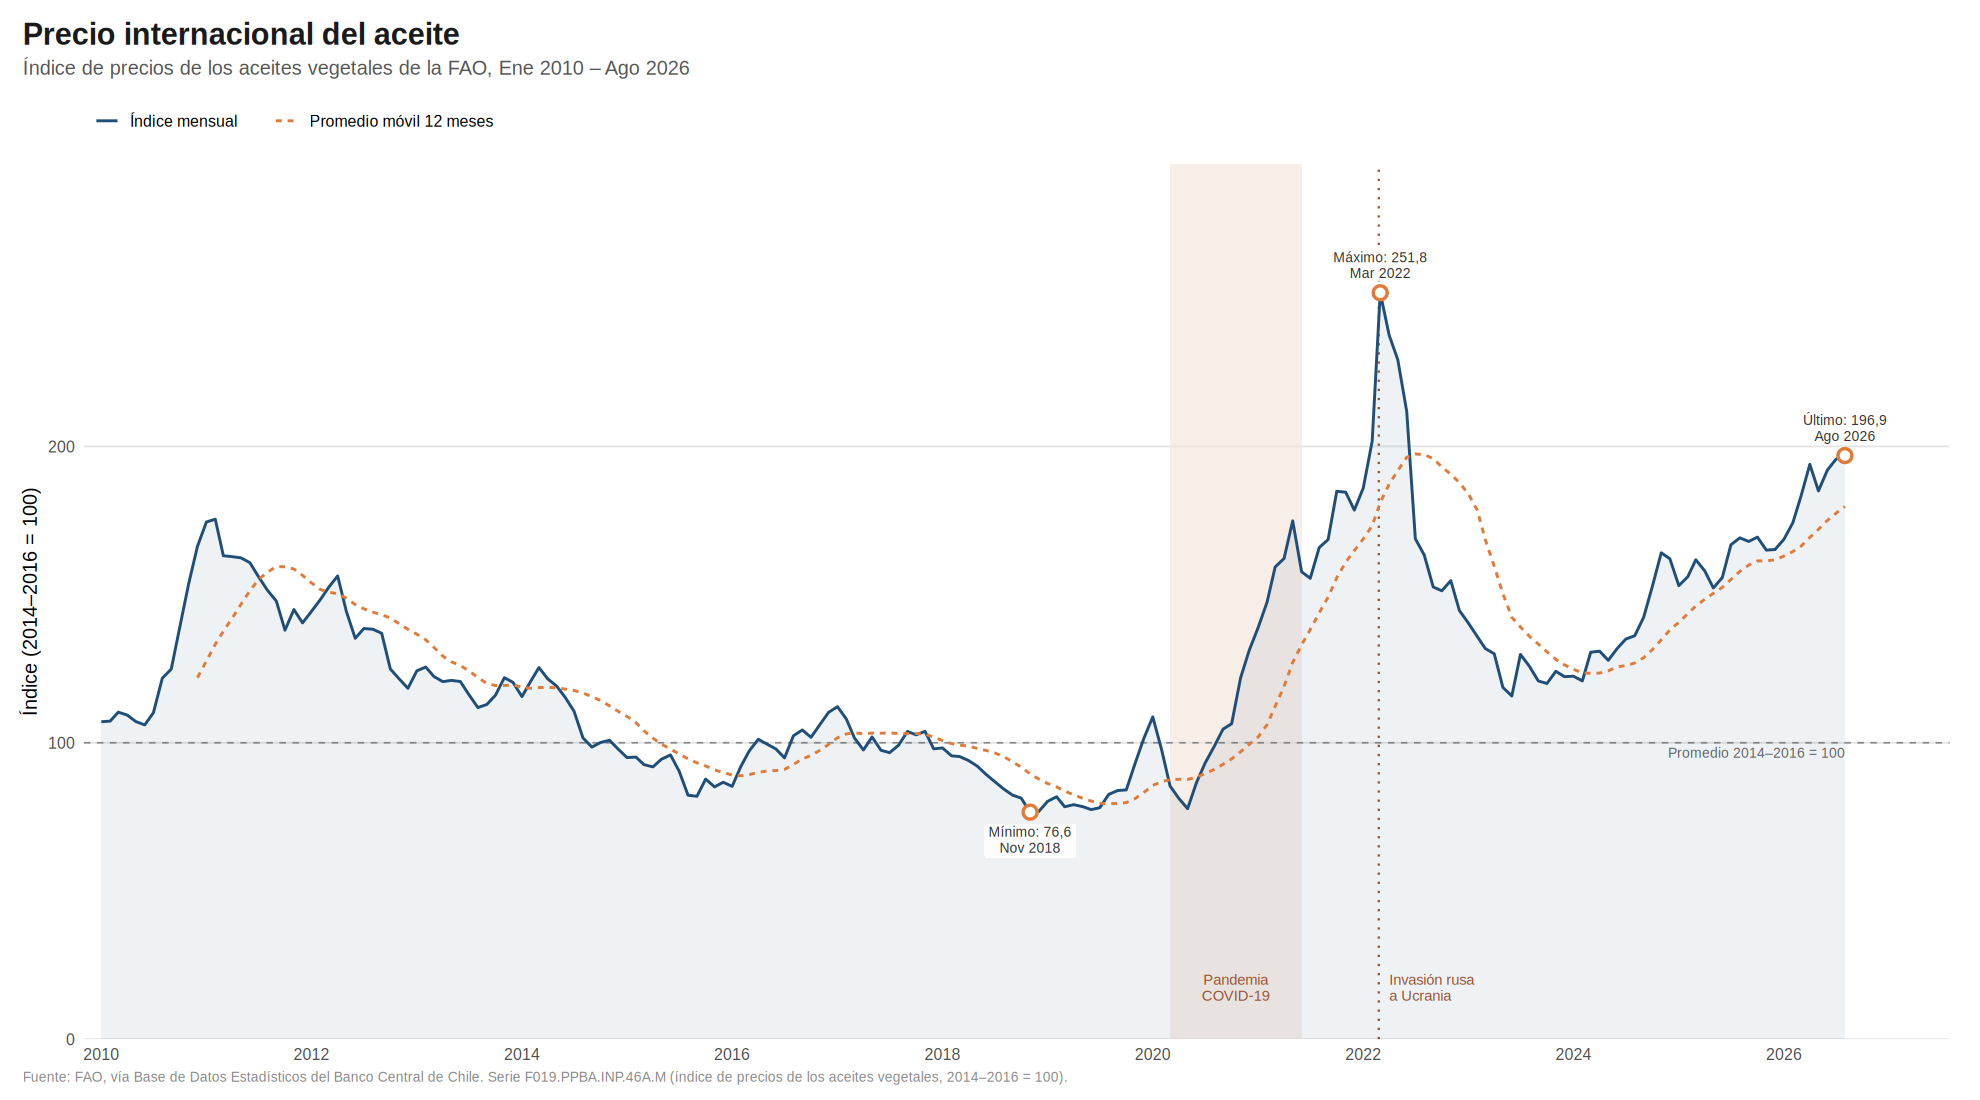

In [4]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

# valores que dependen de la escala de la serie (en la desocupación eran máximo + 2.2 y y = 1.2)
y_max <- max(df$indice) * 1.15   # techo del eje: 15% sobre el máximo para que quepa su etiqueta
y_txt <- y_max * 0.06            # altura de los textos de los episodios (franja inferior del gráfico)

# arma una pequeña tabla llamada hitos con los tres puntos que se destacan: el máximo, el mínimo y el último dato.
# vj es la posición vertical de la etiqueta: sobre el punto (-0.35) o bajo el punto (1.35), para no tapar la línea
hitos <- bind_rows(
  df |> slice_max(indice, n = 1) |> mutate(txt = paste0("Máximo: ", num_es(indice), "\n", etq_fecha(fecha)), vj = -0.35),
  df |> slice_min(indice, n = 1) |> mutate(txt = paste0("Mínimo: ", num_es(indice), "\n", etq_fecha(fecha)), vj = 1.35),
  df |> slice_tail(n = 1)      |> mutate(txt = paste0("Último: ", num_es(indice), "\n", etq_fecha(fecha)), vj = -0.35)
)

# construye el gráfico (la serie de tiempo) y lo guarda como g1
g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  annotate("text", x = as.Date("2020-10-15"), y = y_txt, label = "Pandemia\nCOVID-19",
           size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_vline(xintercept = as.Date("2022-02-24"), colour = "#A0522D", linetype = "dotted", linewidth = .7) +
  annotate("text", x = as.Date("2022-04-01"), y = y_txt, label = "Invasión rusa\na Ucrania",
           hjust = 0, size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_hline(yintercept = 100, colour = "#888888", linetype = "dashed", linewidth = .5) +
  annotate("text", x = max(df$fecha), y = 100, label = "Promedio 2014–2016 = 100",
           hjust = 1, vjust = 1.5, size = 3.2, colour = "#666666") +
  geom_area(aes(y = indice), fill = col_principal, alpha = .07) +
  geom_line(aes(y = indice, colour = "Índice mensual"), linewidth = .9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = .9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = indice), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = indice, label = txt, vjust = vj), size = 3.2,
             linewidth = 0, fill = alpha("white", .85), colour = "#333333", lineheight = .95) +
  scale_colour_manual(NULL, values = c("Índice mensual" = col_principal,
                                       "Promedio móvil 12 meses" = col_acento),
                      breaks = c("Índice mensual", "Promedio móvil 12 meses")) +
  scale_x_date(breaks = seq(as.Date(paste0(min(df$anio), "-01-01")), max(df$fecha), by = "2 years"),
               date_labels = "%Y", expand = expansion(mult = c(.01, .06))) +
  scale_y_continuous(labels = label_number(accuracy = 1),
                     limits = c(0, y_max), expand = expansion(mult = c(0, .02))) +
  labs(title = "Precio internacional del aceite",
       subtitle = paste0("Índice de precios de los aceites vegetales de la FAO, ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = NULL, y = "Índice (2014–2016 = 100)", caption = fuente) +
  tema

g1

In [5]:
# Cifras que respaldan la interpretación del gráfico
# promedio, mínimo y máximo del índice en cada año (2026 tiene 8 meses)
df |>
  group_by(anio) |>
  summarise(promedio = round(mean(indice), 1), minimo = round(min(indice), 1),
            maximo = round(max(indice), 1), meses = n())

# última vez que el índice estuvo por sobre el último dato
ultimo_valor <- tail(df$indice, 1)
previo <- df |> filter(indice > ultimo_valor) |> slice_tail(n = 1)
cat("Último dato:", num_es(ultimo_valor), "| última vez que el índice fue mayor:",
    paste0(etq_fecha(previo$fecha), " (", num_es(previo$indice), ")"), "\n")

# máximo del promedio móvil de 12 meses
pm <- df |> filter(!is.na(media_12m)) |> slice_max(media_12m, n = 1)
cat("Máximo del promedio móvil:", num_es(pm$media_12m), "en", etq_fecha(pm$fecha), "\n")

anio,promedio,minimo,maximo,meses
<int>,<dbl>,<dbl>,<dbl>,<int>
2010,122.0,106.0,166.3,12
2011,156.5,138.0,175.4,12
2012,138.3,118.4,156.3,12
2013,119.5,111.9,125.5,12
2014,110.6,97.9,125.4,12
2015,89.9,82.0,95.9,12
2016,99.4,85.3,110.3,12
2017,101.9,96.7,112.2,12
2018,87.8,76.6,98.3,12


Último dato: 196,9 | última vez que el índice fue mayor: Jun 2022 (211,8) 
Máximo del promedio móvil: 197,4 en Jul 2022 


## 5. Mapa de calor por año y mes
Cada fila es un año, cada columna es un mes y el color indica el nivel del índice. El gráfico permite responder dos preguntas: qué años fueron caros o baratos, comparando filas, y si existe un patrón estacional, comparando columnas.

**Umbral del texto blanco.** En el original, los números se escribían en blanco cuando la tasa superaba 10%, porque desde ese nivel el fondo era demasiado oscuro para el texto negro. Ese 10 no tiene sentido en un índice que va de 76,6 a 251,8, así que el umbral se recalculó con la misma lógica. Primero se mide la distancia entre el mínimo y el máximo del índice, que es de 175,2 puntos. Luego se toma el 55% de esa distancia, 96,4 puntos, y se suma al mínimo, lo que da un umbral de 173,0 puntos. La proporción es parecida a la del original: allí, el 10% quedaba al 58% de la distancia entre el mínimo (5,8%) y el máximo (13,1%) de la desocupación.

Umbral para texto blanco: 173,0 puntos


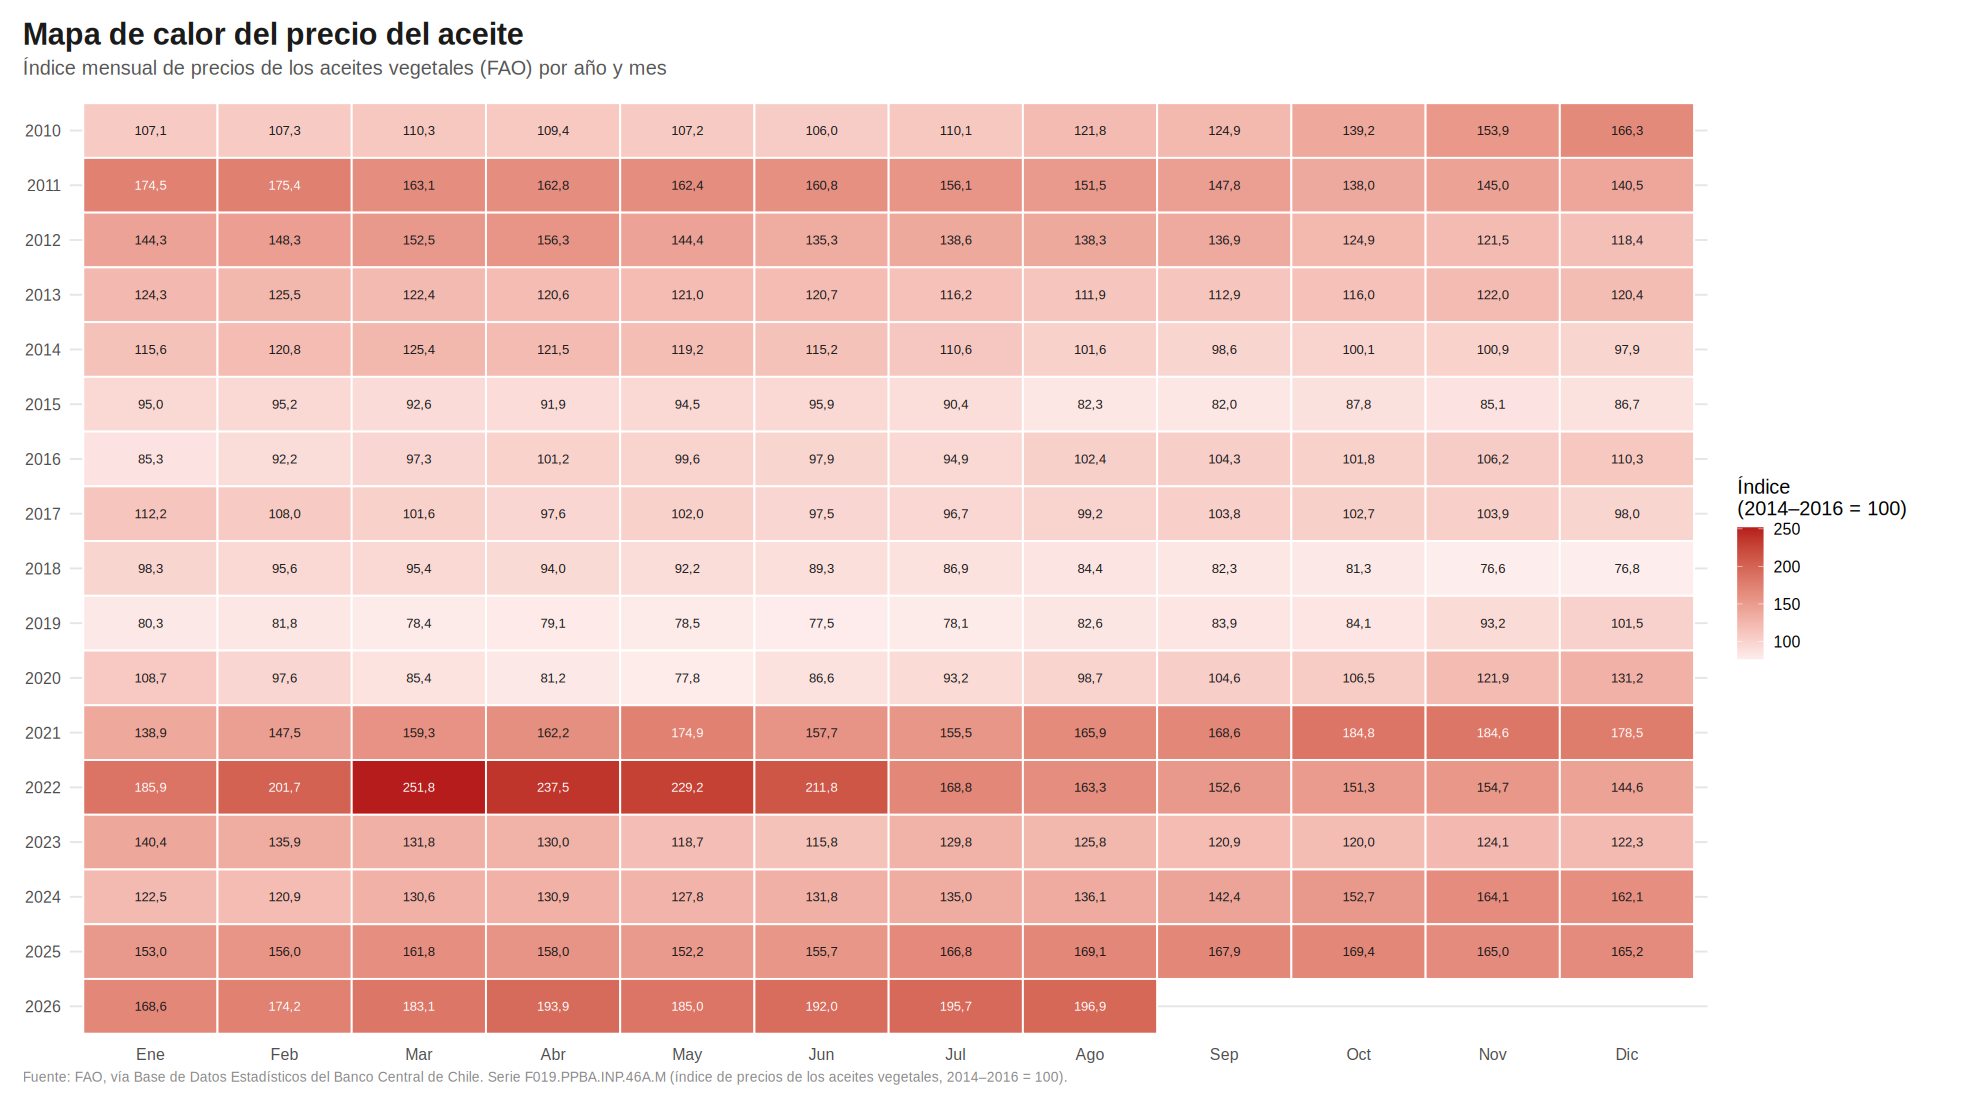

In [6]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# Umbral para escribir los números en blanco. En la desocupación era 10 (%), cifra que no sirve para un índice
# que va de ~77 a ~252. Ese 10 quedaba a ~57% del recorrido de la tasa (5,8% a 13,1%); aquí se usa una posición
# parecida, el 55% del recorrido del índice (≈ 173 puntos), donde el fondo ya es oscuro para el texto negro.
umbral_txt <- min(df$indice) + 0.55 * diff(range(df$indice))
cat("Umbral para texto blanco:", num_es(umbral_txt), "puntos\n")

# construye el mapa de calor y lo guarda como g2
g2 <- ggplot(df, aes(factor(mes, levels = 1:12, labels = meses_es),
                     factor(anio, levels = rev(sort(unique(anio)))),
                     fill = indice)) +
  geom_tile(colour = "white", linewidth = .6) +
  geom_text(aes(label = num_es(indice), colour = indice > umbral_txt), size = 3, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#FDEDEC", high = "#B71C1C", name = "Índice\n(2014–2016 = 100)") +
  labs(title = "Mapa de calor del precio del aceite",
       subtitle = "Índice mensual de precios de los aceites vegetales (FAO) por año y mes",
       x = NULL, y = NULL, caption = fuente) +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

g2

In [7]:
# Comprobación numérica de estacionalidad, solo con años completos (2010-2025):
# para cada mes se calcula cuánto se aleja (en %) del promedio de su año y luego se promedia por mes del calendario
df |>
  group_by(anio) |>
  filter(n() == 12) |>
  mutate(desvio = (indice / mean(indice) - 1) * 100) |>
  group_by(mes) |>
  summarise(desvio_promedio = round(mean(desvio), 1)) |>
  mutate(mes = meses_es[mes])

mes,desvio_promedio
<chr>,<dbl>
Ene,0.6
Feb,1.2
Mar,2.5
Abr,1.3
May,-0.2
Jun,-2.0
Jul,-2.9
Ago,-2.6
Sep,-2.3


## 6. Variación en 12 meses
Cada barra muestra en qué porcentaje subió (naranjo) o bajó (azul) el índice respecto del mismo mes del año anterior, calculado como se explicó en la sección 2. El eje vertical está en porcentaje, con marcas cada 25%, porque en esta serie las variaciones van aproximadamente de −50% a +125%. En el original las marcas iban cada 1 punto porcentual, porque la desocupación variaba solo unos pocos puntos.

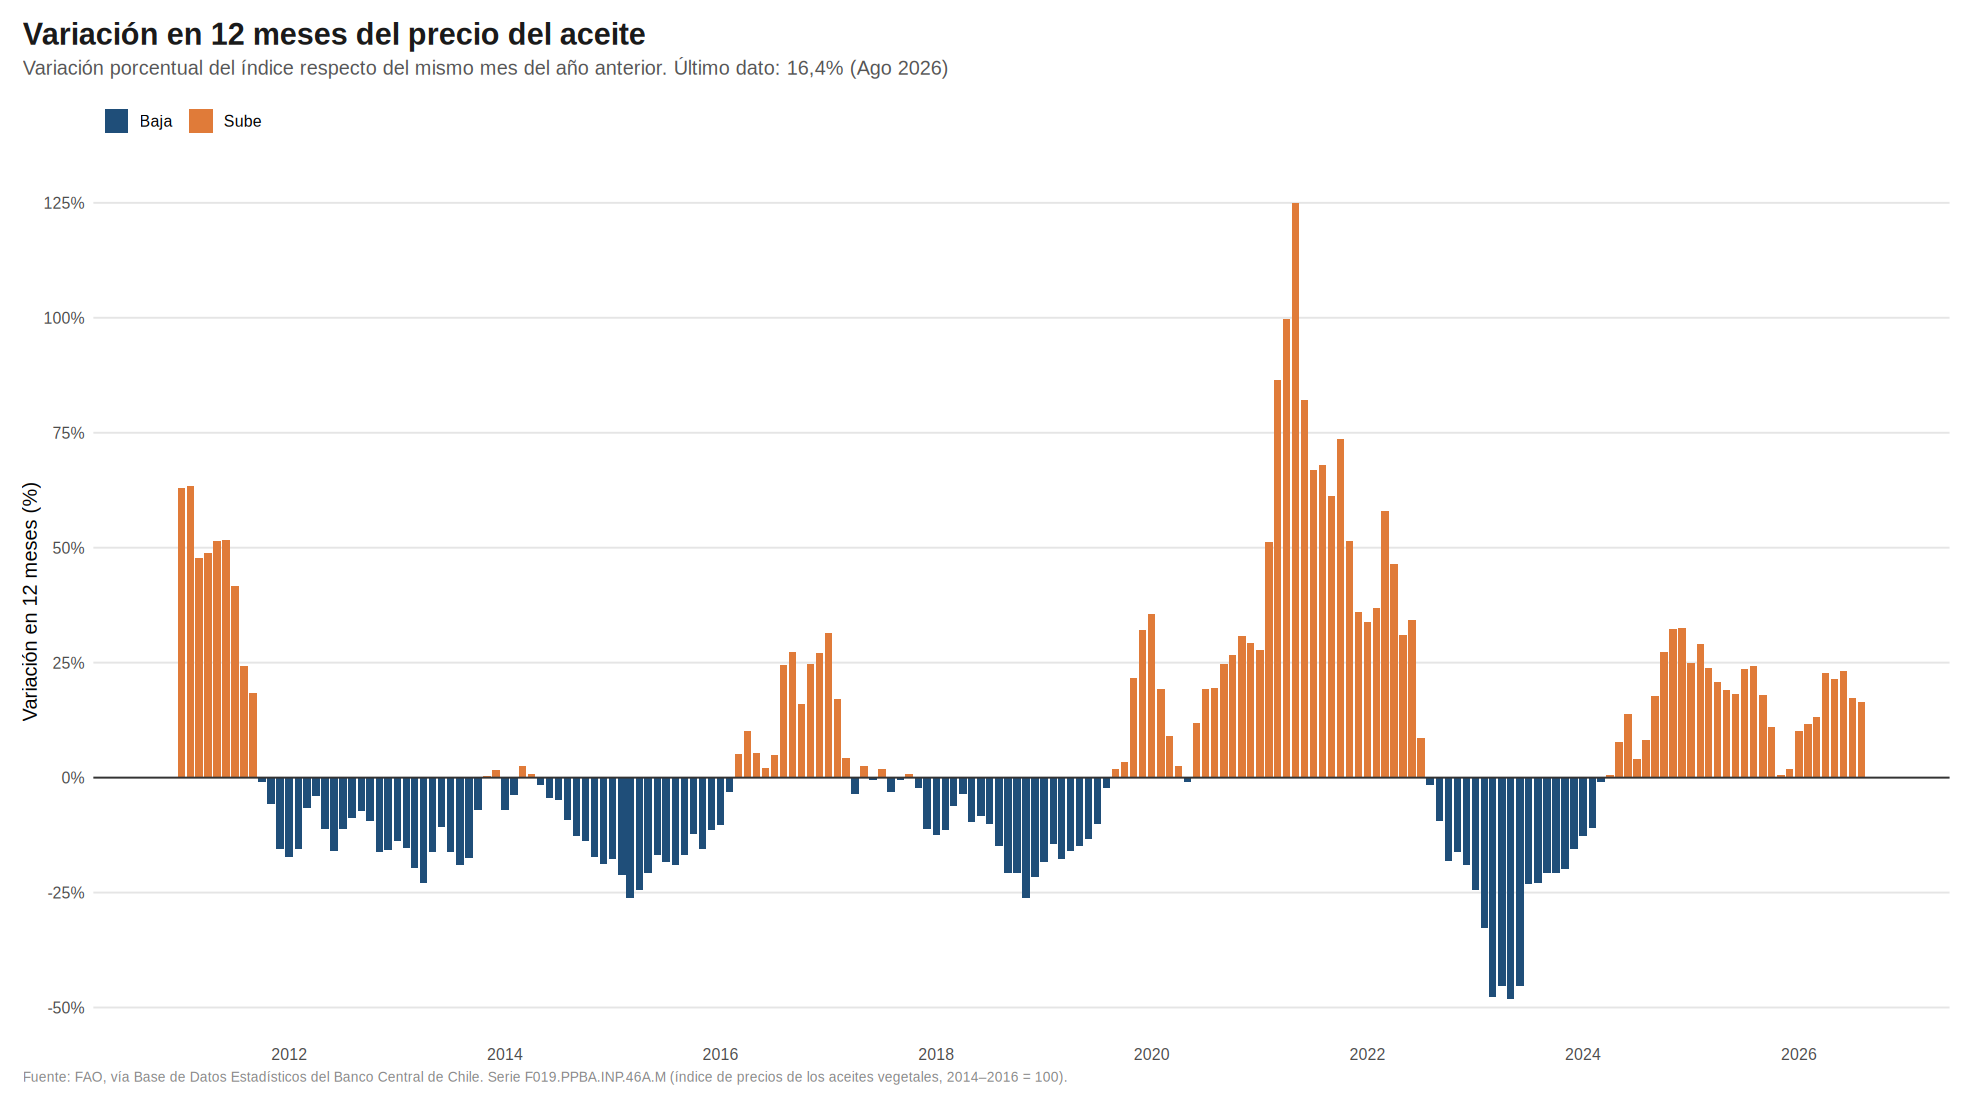

In [8]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

ultimo <- df |> slice_tail(n = 1)   # último dato, para el subtítulo

# construye el gráfico de barras de la variación en 12 meses y lo guarda como g3
g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(fecha, var_12m, fill = var_12m > 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333") +
  scale_fill_manual(NULL, values = c(`TRUE` = col_acento, `FALSE` = col_principal),
                    labels = c(`TRUE` = "Sube", `FALSE` = "Baja")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(breaks = breaks_width(25), labels = label_number(accuracy = 1, suffix = "%")) +
  labs(title = "Variación en 12 meses del precio del aceite",
       subtitle = paste0("Variación porcentual del índice respecto del mismo mes del año anterior. Último dato: ",
                         num_es(ultimo$var_12m), "% (", etq_fecha(ultimo$fecha), ")"),
       x = NULL, y = "Variación en 12 meses (%)", caption = fuente) +
  tema

g3

In [9]:
# Cifras que respaldan la interpretación del gráfico
v <- df |> filter(!is.na(var_12m))
cat("Meses con alza:", sum(v$var_12m > 0), "| con baja:", sum(v$var_12m < 0), "| total:", nrow(v), "\n")

# variaciones extremas
bind_rows(v |> slice_max(var_12m, n = 1), v |> slice_min(var_12m, n = 1)) |>
  select(fecha, indice, var_12m)

# racha actual: cuántos meses seguidos, hasta el último dato, la variación tiene el mismo signo
racha <- rle(v$var_12m > 0)
cat("Racha actual:", tail(racha$lengths, 1), "meses seguidos",
    ifelse(tail(racha$values, 1), "con alza", "con baja"), "\n")

Meses con alza: 92 | con baja: 96 | total: 188 


fecha,indice,var_12m
<date>,<dbl>,<dbl>
2021-05-01,174.8759,124.86623
2023-05-01,118.6824,-48.22808


Racha actual: 29 meses seguidos con alza 


## 7. Guardar los gráficos en PNG
Quedan en el panel de archivos; clic derecho → Descargar.

In [10]:
ggsave("aceite_serie.png",        g1, width = 12, height = 6.5, dpi = 300)
ggsave("aceite_mapa_calor.png",   g2, width = 11, height = 8,   dpi = 300)
ggsave("aceite_variacion12m.png", g3, width = 12, height = 5.5, dpi = 300)
list.files(pattern = "^aceite_.*\\.png$")

[1] "aceite_mapa_calor.png"   "aceite_serie.png"       
[3] "aceite_variacion12m.png"

## 8. Interpretación

**¿Cuál es el valor más reciente y cómo se compara con el promedio del período?**
El último dato, de agosto de 2026, es 196,9 puntos, el más alto desde junio de 2022. Supera en 70,2 puntos al promedio del período (126,7), es decir, es un 55% más alto, y está 96,9% sobre la base de 2014–2016. No es un dato aislado: los últimos 12 meses están todos entre el 25% de meses más caros de la serie.

**¿Cuándo ocurrieron el máximo y el mínimo, y qué eventos económicos podrían explicarlos?**
El máximo fue 251,8 puntos en marzo de 2022, un mes después de la invasión rusa a Ucrania. Ambos países aportaban cerca del 77% de las exportaciones mundiales de aceite de girasol, y la guerra cortó ese suministro cuando la oferta ya estaba estrecha por sequías en Canadá y Sudamérica. Luego Indonesia prohibió exportar aceite de palma entre abril y mayo, lo que ayudó a mantener el índice sobre 200 hasta junio. El mínimo fue 76,6 puntos en noviembre de 2018, tras diez caídas mensuales seguidas. Según la FAO, se explicó por grandes inventarios de aceite de palma y una oferta abundante de aceites de soya y girasol, junto con un petróleo más barato.

**¿Se observa un patrón estacional en el mapa de calor? ¿En qué meses?**
Solo uno débil. En promedio, de junio a septiembre el índice queda entre 2% y 3% bajo el promedio de su año (julio, 2,9% bajo) y de noviembre a abril algo sobre él (diciembre, 3,0% sobre). Son diferencias pequeñas frente a las que hay entre años: el promedio anual pasó de 83,2 en 2019 a 187,8 en 2022. Por eso el mapa se lee por filas, no por columnas.

**¿Qué muestra la variación en 12 meses sobre la tendencia actual?**
Una tendencia alcista que se modera. La variación es positiva desde abril de 2024, 29 meses seguidos, y en agosto de 2026 fue de 16,4%, por debajo del 23,3% de junio: el precio sigue subiendo, pero más lento. El promedio móvil de 12 meses también sube desde abril de 2024, lo que confirma la tendencia. Según la FAO, el alza de 2026 la lidera el aceite de palma, por la demanda para biocombustibles y el petróleo más caro.